# Variance reduction in A/B tests with CUPED

A worked example on **synthetic data**: a marketplace runs an experiment on a cashback-style incentive and wants to know whether it changes **orders per user**.

The question this notebook answers: *how much does CUPED (using each user's pre-experiment behaviour as a covariate) tighten the estimate — and does it stay honest?*

Structure:
1. Simulate users with a stable underlying propensity to order
2. Estimate the effect with a plain difference in means
3. Estimate it again with CUPED and compare confidence intervals
4. A/A check: does CUPED keep the false positive rate at 5%?
5. Power: how often each method detects a real +3% effect


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## 1. Synthetic data

Each user has a latent propensity to order (Gamma-distributed, so a few heavy users and a long tail of light ones). The **pre-period metric** is orders in the 4 weeks before the test; the **test metric** is orders during the 4-week test. Both depend on the same propensity, which is exactly why the pre-period is a useful covariate.

Treatment multiplies the order rate by `1 + lift`.

In [2]:
def simulate(n_per_arm, lift, rng):
    n = 2 * n_per_arm
    propensity = rng.gamma(shape=0.8, scale=1.5, size=n)     # orders per 4 weeks
    group = np.repeat(["control", "treatment"], n_per_arm)
    pre = rng.poisson(propensity)                              # 4 weeks before the test
    rate = propensity * np.where(group == "treatment", 1 + lift, 1.0)
    post = rng.poisson(rate)                                   # 4 weeks of the test
    return pd.DataFrame({"group": group, "pre_orders": pre, "orders": post})

df = simulate(n_per_arm=20_000, lift=0.03, rng=rng)
df.groupby("group")[["pre_orders", "orders"]].mean().round(3)

,pre_orders,orders
group,,
control,1.197,1.198
treatment,1.214,1.249


In [3]:
corr = df[["pre_orders", "orders"]].corr().iloc[0, 1]
print(f"Correlation between pre-period and test-period orders: {corr:.2f}")
print(f"Expected variance reduction from CUPED ≈ corr² = {corr**2:.0%}")

Correlation between pre-period and test-period orders: 0.60
Expected variance reduction from CUPED ≈ corr² = 36%


## 2. Baseline: difference in means

Welch's t-test on orders per user, reported as an absolute difference with a 95% confidence interval and as a relative lift.

In [4]:
def diff_in_means(y, group):
    a, b = y[group == "control"], y[group == "treatment"]
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    p = 2 * stats.norm.sf(abs(diff / se))
    return {"diff": diff, "ci_low": diff - 1.96 * se, "ci_high": diff + 1.96 * se,
            "se": se, "p_value": p, "rel_lift": diff / a.mean()}

naive = diff_in_means(df["orders"].to_numpy(), df["group"].to_numpy())
pd.Series(naive).round(4)

diff        0.0511
ci_low      0.0165
ci_high     0.0857
se          0.0176
p_value     0.0038
rel_lift    0.0427
dtype: float64

## 3. CUPED

CUPED replaces the metric `Y` with an adjusted version that removes the part explained by the pre-period covariate `X`:

```
Y_cuped = Y − θ · (X − mean(X)),   θ = cov(X, Y) / var(X)
```

Two details that matter in practice:
- **θ is estimated on both groups pooled**, not per group — otherwise the adjustment can absorb part of the treatment effect.
- `X` must be measured **before** assignment, so the treatment cannot affect it. Then `mean(Y_cuped)` differs between groups by the same expected amount as `mean(Y)` — the estimate stays unbiased, only the noise shrinks.


In [5]:
def cuped_adjust(y, x):
    theta = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), theta

y_cuped, theta = cuped_adjust(df["orders"].to_numpy(float), df["pre_orders"].to_numpy(float))
cuped = diff_in_means(y_cuped, df["group"].to_numpy())
print(f"theta = {theta:.3f}")

comparison = pd.DataFrame({"Difference in means": naive, "CUPED": cuped}).T
comparison["ci_width"] = comparison["ci_high"] - comparison["ci_low"]
comparison[["diff", "rel_lift", "ci_low", "ci_high", "ci_width", "p_value"]].round(4)

theta = 0.604


,diff,rel_lift,ci_low,ci_high,ci_width,p_value
Difference in means,0.0511,0.0427,0.0165,0.0857,0.0691,0.0038
CUPED,0.0412,0.0342,0.0135,0.0688,0.0554,0.0036


The two point estimates differ, and that is expected. By chance, the treatment group was already ordering slightly more **before** the test started. A plain difference in means counts that pre-existing gap as part of the effect; CUPED subtracts it. In this simulation the true lift is +3%, so the check below shows which estimate lands closer.

In [6]:
pre = df.groupby("group")["pre_orders"].mean()
print(f"Pre-period gap (treatment vs control): {pre['treatment'] / pre['control'] - 1:+.1%}")
print(f"True lift: +3.0% | difference in means: {naive['rel_lift']:+.1%} | CUPED: {cuped['rel_lift']:+.1%}")

Pre-period gap (treatment vs control): +1.4%
True lift: +3.0% | difference in means: +4.3% | CUPED: +3.4%


In [7]:
var_reduction = 1 - np.var(y_cuped, ddof=1) / df["orders"].var(ddof=1)
ci_shrink = 1 - comparison.loc["CUPED", "ci_width"] / comparison.loc["Difference in means", "ci_width"]
print(f"Variance reduction: {var_reduction:.0%}")
print(f"Confidence interval narrower by: {ci_shrink:.0%}")
print(f"Sample needed for the same precision: {1 - var_reduction:.0%} of the original")

Variance reduction: 36%
Confidence interval narrower by: 20%
Sample needed for the same precision: 64% of the original


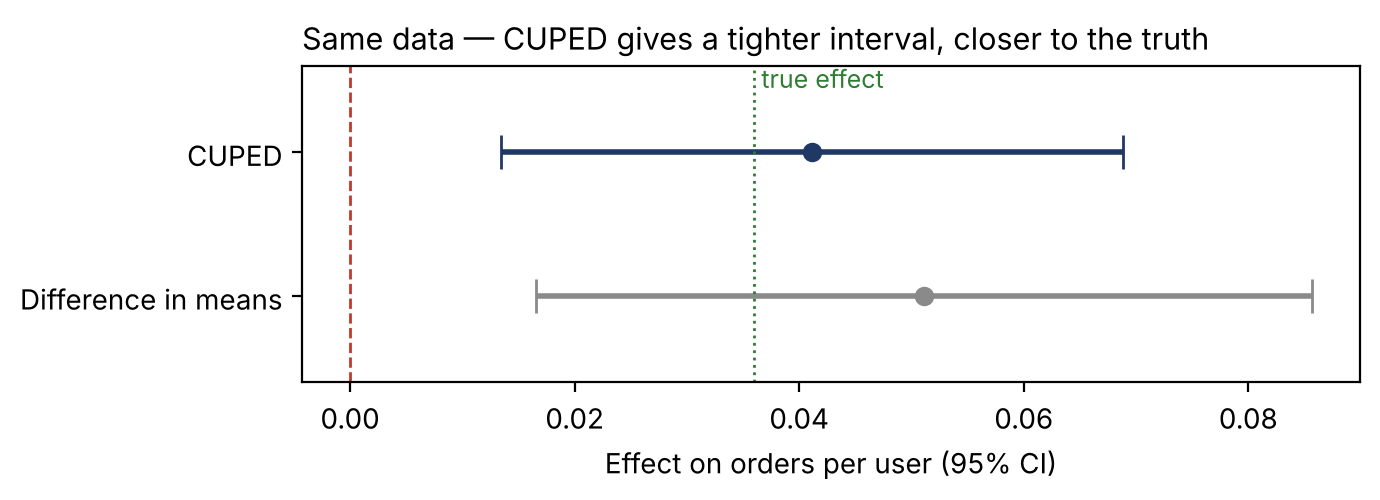

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, name in enumerate(["Difference in means", "CUPED"]):
    r = comparison.loc[name]
    ax.errorbar(r["diff"], i, xerr=[[r["diff"] - r["ci_low"]], [r["ci_high"] - r["diff"]]],
                fmt="o", capsize=6, color=["#8a8a8a", "#1f3864"][i], lw=2)
ax.axvline(0, color="#c0392b", lw=1, ls="--")
true_effect = 0.03 * 0.8 * 1.5          # lift × mean propensity used in the simulation
ax.axvline(true_effect, color="#2e7d32", lw=1, ls=":")
ax.text(true_effect, 1.45, " true effect", color="#2e7d32", fontsize=9)
ax.set_yticks([0, 1], ["Difference in means", "CUPED"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Effect on orders per user (95% CI)")
ax.set_title("Same data — CUPED gives a tighter interval, closer to the truth", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig("ci_comparison.png", dpi=150)
plt.show()

## 4. A/A check: is CUPED still honest?

A variance-reduction method is only useful if it doesn't inflate false positives. Simulate 1,000 experiments with **no real effect** and count how often each method declares significance at α = 0.05. Both should land near 5%.

In [9]:
def run_many(n_sims, n_per_arm, lift, rng, alpha=0.05):
    hits = {"naive": 0, "cuped": 0}
    for _ in range(n_sims):
        d = simulate(n_per_arm, lift, rng)
        g = d["group"].to_numpy()
        y = d["orders"].to_numpy(float)
        yc, _ = cuped_adjust(y, d["pre_orders"].to_numpy(float))
        hits["naive"] += diff_in_means(y, g)["p_value"] < alpha
        hits["cuped"] += diff_in_means(yc, g)["p_value"] < alpha
    return {k: v / n_sims for k, v in hits.items()}

aa = run_many(n_sims=1_000, n_per_arm=5_000, lift=0.0, rng=rng)
print(f"False positive rate — difference in means: {aa['naive']:.1%}, CUPED: {aa['cuped']:.1%}")

False positive rate — difference in means: 5.0%, CUPED: 4.9%


## 5. Power: how often is a real +3% effect detected?

Same simulation, now with a true +3% lift, at several sample sizes.

In [10]:
sizes = [5_000, 10_000, 20_000, 40_000]
power = pd.DataFrame([{"users_per_arm": n, **run_many(300, n, 0.03, rng)} for n in sizes])
power.columns = ["users_per_arm", "difference in means", "CUPED"]
power

,users_per_arm,difference in means,CUPED
0,5000,0.166667,0.253333
1,10000,0.316667,0.423333
2,20000,0.570000,0.753333
3,40000,0.836667,0.960000


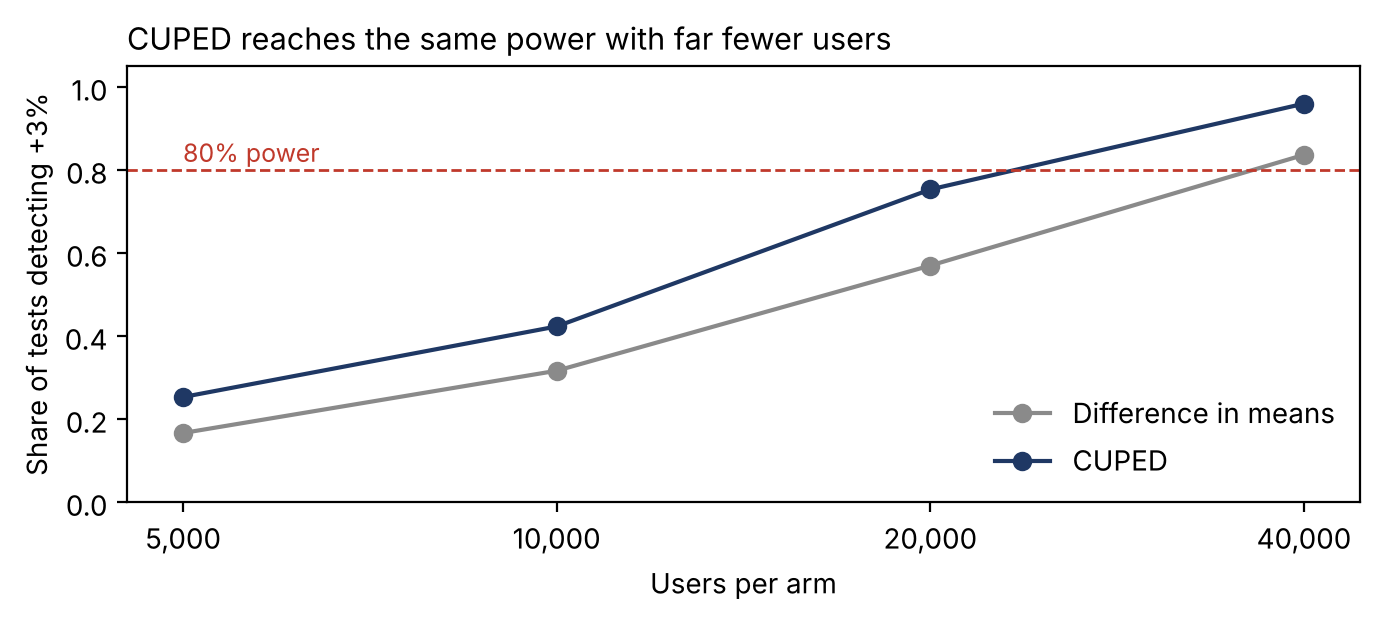

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(power["users_per_arm"], power["difference in means"], "o-", color="#8a8a8a", label="Difference in means")
ax.plot(power["users_per_arm"], power["CUPED"], "o-", color="#1f3864", label="CUPED")
ax.axhline(0.8, color="#c0392b", lw=1, ls="--")
ax.text(sizes[0], 0.82, "80% power", color="#c0392b", fontsize=9)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks(sizes, [f"{n:,}" for n in sizes])
ax.set_ylim(0, 1.05)
ax.set_xlabel("Users per arm")
ax.set_ylabel("Share of tests detecting +3%")
ax.legend(frameon=False, loc="lower right")
ax.set_title("CUPED reaches the same power with far fewer users", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig("power_curve.png", dpi=150)
plt.show()

## Takeaways

- With a pre-period metric that correlates with the outcome, CUPED cuts variance roughly by `corr²` — here enough to need a fraction of the sample for the same precision.
- The point estimate doesn't move in expectation; only the noise around it shrinks. In any single test it also corrects chance pre-period imbalance between groups.
- The A/A check keeps the false positive rate at the nominal level, so the gain is not bought with extra false alarms.

**Where it needs care in production**
- New users have no pre-period: give them `X = 0` plus a "new user" indicator, or analyse them as a separate stratum.
- Choose the covariate window to match the metric (same metric, same length of period works best).
- Heavy-tailed metrics such as revenue: cap outliers before computing θ, or the adjustment gets noisy.
